<a href="https://colab.research.google.com/github/Hesandu-Ruwanpathirana/Hesandu-Ruwanpathirana/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction
## 1. Loading and Inspecting the Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


# Makes the charts look cleaner
sns.set_style("whitegrid")

In [2]:
url = "https://raw.githubusercontent.com/Hesandu-Ruwanpathirana/telco-customer-churn-prediction/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Shows how many rows and columns we have
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# Finds rows where TotalCharges is just a blank space
blank_rows = df[df["TotalCharges"] == " "]
print("Blank TotalCharges rows:", len(blank_rows))
blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Section 1 findings:**
- The dataset contains 7,043 customers and 21 columns.
- Each row is one customer, with information on demographics (gender, SeniorCitizen, Partner, Dependents), account details (tenure, Contract, PaymentMethod, PaperlessBilling, MonthlyCharges, TotalCharges) and services (PhoneService, InternetService, OnlineSecurity, TechSupport, StreamingTV, etc.).
- The target variable is Churn (Yes/No), indicating whether the customer left within the last month.
- Most columns are categorical (text), so they will need to be converted to numbers before modelling.
- TotalCharges was stored as text (object) instead of a number. Investigation showed 11 rows containing a blank space instead of a value.
- All 11 of these customers have a tenure of 0, meaning they are new customers who have not yet been billed.

## 2. Data Cleaning

In [5]:
# Replaces blank spaces with 0 because these customers have tenure 0
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0")

# Converts the column from text to a number
df["TotalCharges"] = df["TotalCharges"].astype(float)

print(df["TotalCharges"].dtype)

float64


In [6]:
# Removes the ID column since it has no predictive value
df = df.drop(columns=["customerID"])

print(df.shape)

(7043, 20)


In [7]:
# Counts missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Counts fully repeated rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 22


In [8]:
# Shows how many customers churned vs stayed
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


**Section 2 findings:**
- The 11 blank TotalCharges values were replaced with 0, since these customers have tenure 0 and have not been charged yet. TotalCharges was then converted to a numeric (float) type.
- customerID was removed because it is a unique identifier with no predictive value.
- After cleaning, there are no missing values in any column. The blank values were not detected by isnull() because they were stored as a space character rather than as empty values.
- 22 duplicate rows were found after removing customerID. These were kept, as they represent different customers who happen to share identical attributes rather than data-entry errors.
- The target is imbalanced: 5,174 customers (73.5%) did not churn and 1,869 (26.5%) did. A model predicting "No" for everyone would reach 73.5% accuracy while catching no churners, so recall, F1-score and ROC-AUC will be used alongside accuracy, together with stratified splitting and class weighting.

## 3. Exploratory Data Analysis

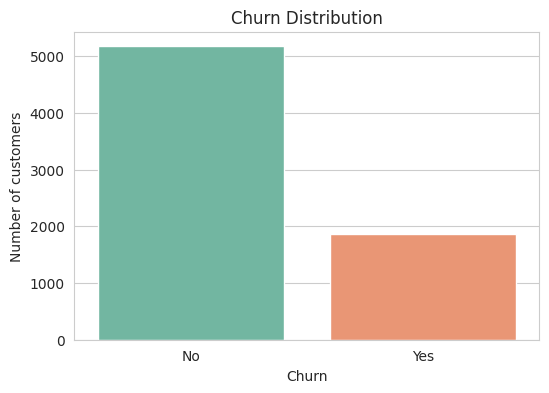

In [9]:
# Bar chart of how many customers churned vs stayed
plt.figure(figsize=(6, 4))
sns.countplot(x="Churn",hue = "Churn" , data=df, palette="Set2")
plt.title("Churn Distribution")
plt.ylabel("Number of customers")
plt.show()

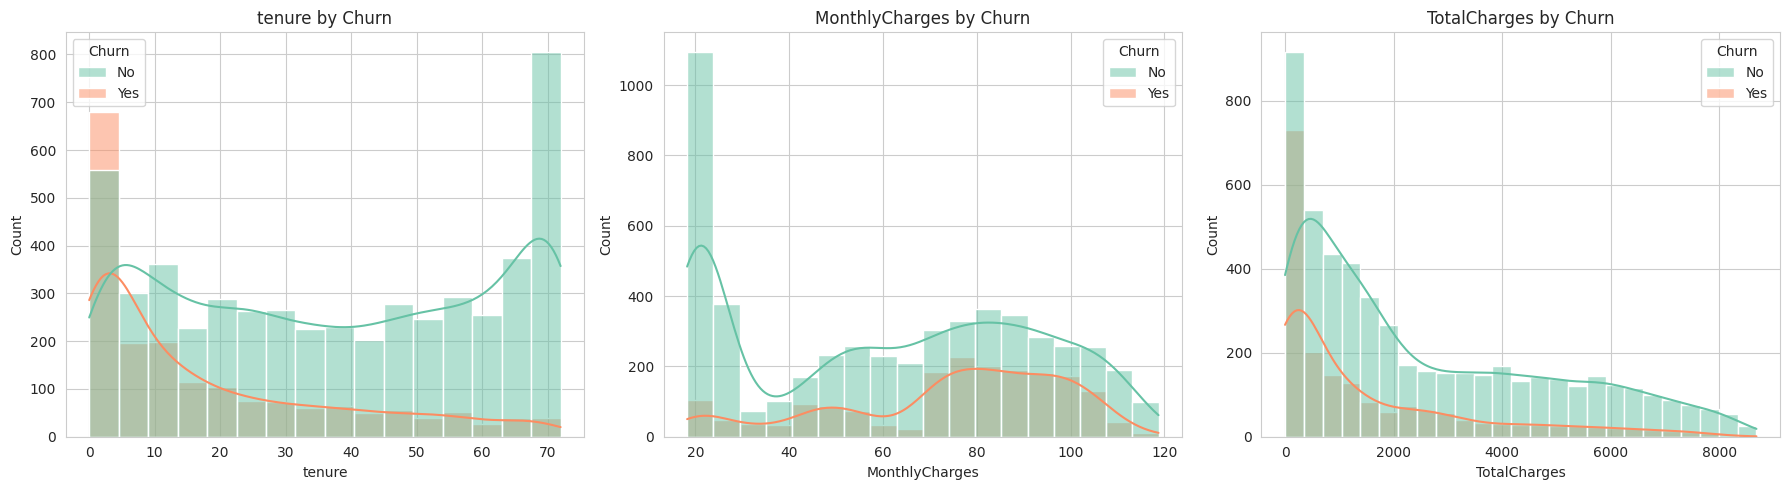

In [10]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# One histogram per number column, coloured by churn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(len(num_cols)):
    col = num_cols[i]
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=axes[i], palette="Set2")
    axes[i].set_title(col + " by Churn")
plt.tight_layout()
plt.show()


**Insights from numerical features:**
- Tenure: churn is concentrated among new customers (0–6 months); in the first few months churners outnumber non-churners. Long-tenure customers (~70 months) rarely churn.
- MonthlyCharges: churners mostly pay $70–$105/month, while many loyal customers pay ~$20 (basic plans). Higher charges are linked with higher churn.
- TotalCharges: right-skewed; churners have low totals because they leave early. This feature largely reflects tenure.

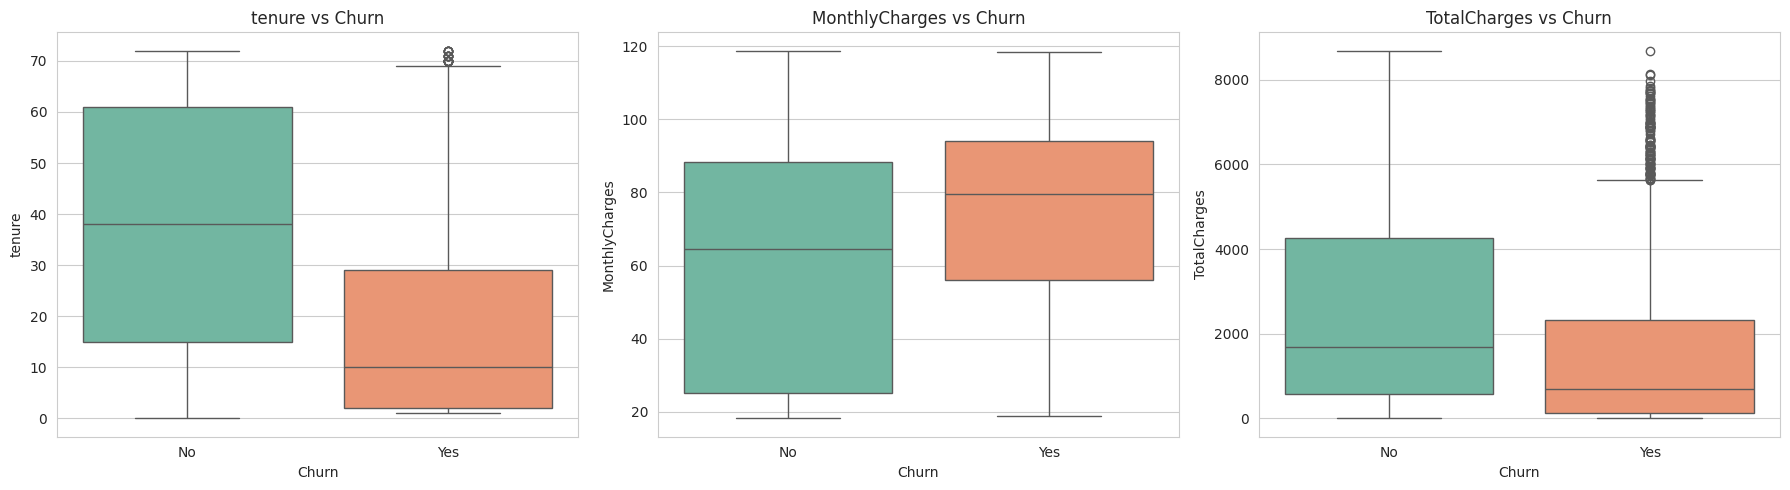

In [11]:
# Box plots comparing churners vs non-churners
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(len(num_cols)):
    col = num_cols[i]
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", legend=False, ax=axes[i], palette="Set2")
    axes[i].set_title(col + " vs Churn")
plt.tight_layout()
plt.show()

**Box plot insights:**
Box plots confirm the histogram findings. Churners have a much lower median tenure (~10 months vs ~38 months), indicating that newer customers are at the highest risk. Churners also pay higher monthly charges (median ~$80 vs ~$65). TotalCharges is lower for churners (median ~$700 vs ~$1,700) mainly because they leave early. Outliers in TotalCharges among churners represent genuine long-tenure customers who eventually left, so they were retained.

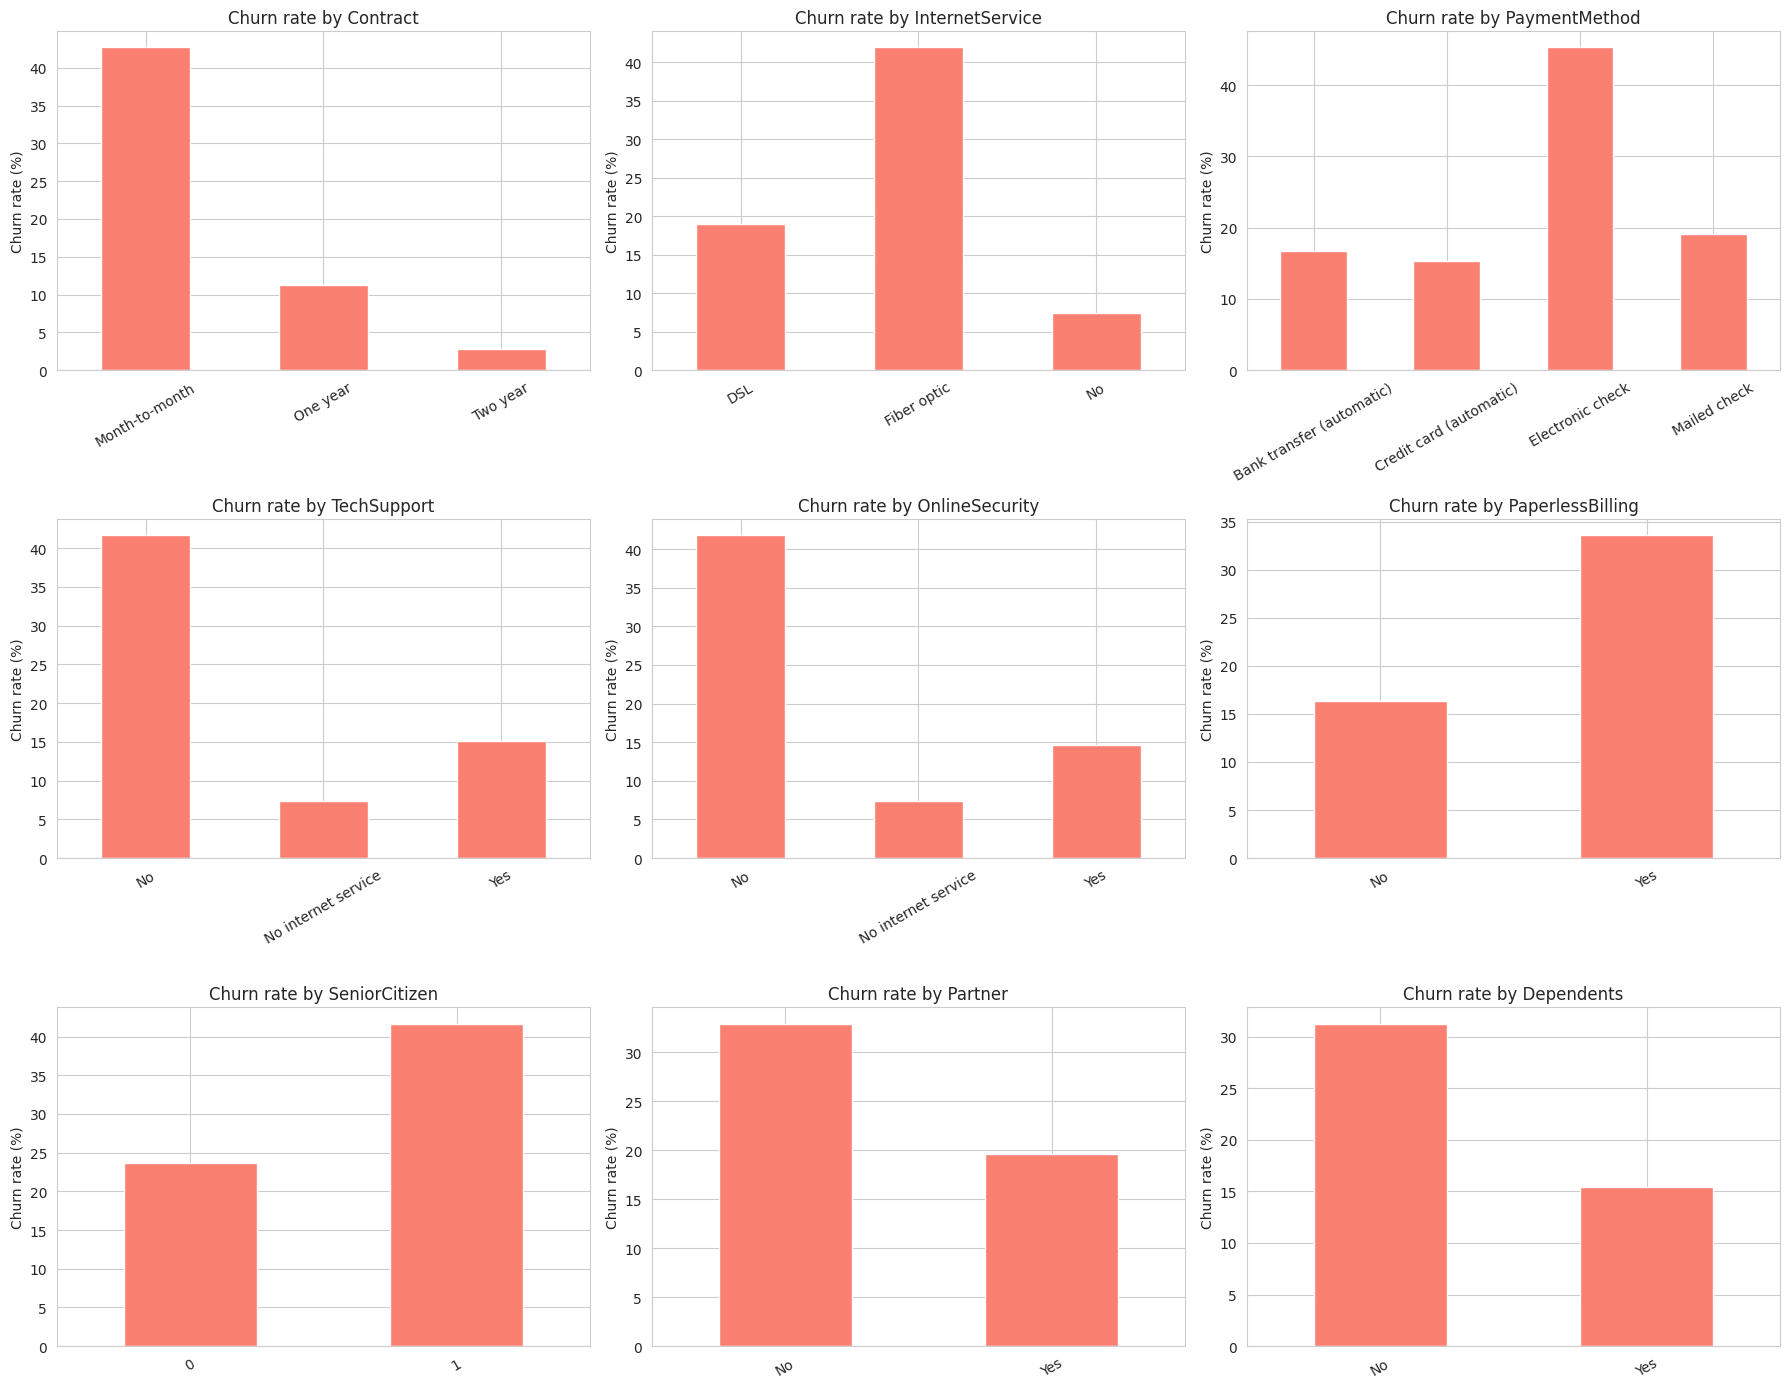

In [12]:
cat_cols = ["Contract", "InternetService", "PaymentMethod",
            "TechSupport", "OnlineSecurity", "PaperlessBilling",
            "SeniorCitizen", "Partner", "Dependents"]

# Churn rate (%) for each group in each category
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()
for i in range(len(cat_cols)):
    col = cat_cols[i]
    rates = pd.crosstab(df[col], df["Churn"], normalize="index") * 100
    rates["Yes"].plot(kind="bar", ax=axes[i], color="salmon")
    axes[i].set_title("Churn rate by " + col)
    axes[i].set_ylabel("Churn rate (%)")
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Churn rate by category:**
Each bar shows the percentage of customers in that group who churned (the remaining percentage stayed). Contract type was the clearest indicator: month-to-month customers churned at ~43%, compared with ~11% for one-year and ~3% for two-year contracts. Fiber optic internet users (~42%) and customers paying by electronic check (~45%) also showed high churn. Customers without tech support or online security churned at roughly three times the rate of those with these services. Senior citizens and customers without partners or dependents were also more likely to churn. These are correlations, not proof of causation.

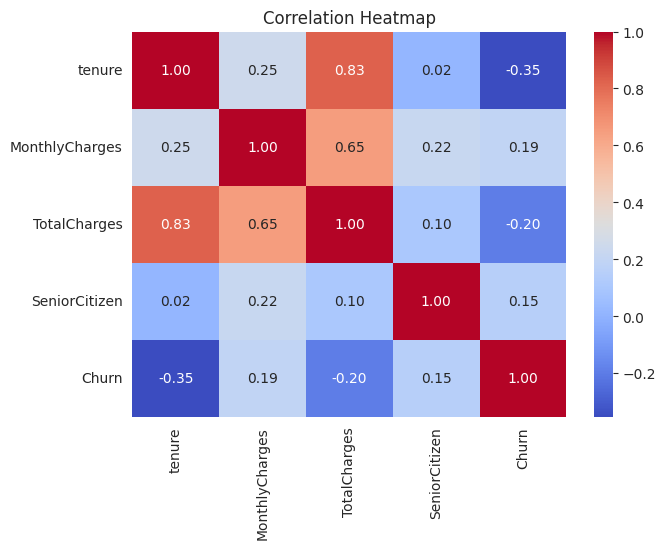

In [13]:
# Copies the number columns and adds churn as 1 or 0
corr_df = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].copy()
corr_df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Correlation insights:**
Tenure had the strongest relationship with churn (r = -0.35), confirming that longer-tenure customers are less likely to leave. MonthlyCharges had a weak positive correlation with churn (r = 0.19). TotalCharges was strongly correlated with tenure (r = 0.83) and MonthlyCharges (r = 0.65), indicating multicollinearity, as TotalCharges is approximately tenure × MonthlyCharges. This was noted as a potential issue for interpreting Logistic Regression coefficients.

**Key EDA insights:**
1. The target is imbalanced (~73% No, ~27% Yes), so recall, F1 and ROC-AUC will be used alongside accuracy.
2. Contract type is the strongest indicator: month-to-month customers churn at ~43% vs ~3% for two-year contracts.
3. New customers are the highest risk: churners have a median tenure of ~10 months vs ~38 for non-churners.
4. Fiber optic users, electronic check payers, and customers without tech support or online security churn far more.
5. Higher monthly charges are associated with higher churn.
6. TotalCharges is highly correlated with tenure (r ≈ 0.83), indicating multicollinearity.

## 4. Data Preprocessing

In [14]:
# Copy of the cleaned data for modelling
data = df.copy()

# Turns Churn into 1 for Yes and 0 for No
data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})

# X is everything except Churn, y is just Churn
X = data.drop(columns=["Churn"])
y = data["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [15]:
# Turns every text column into 0/1 columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("X shape after encoding:", X.shape)
X.head()

X shape after encoding: (7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


Categorical features were one-hot encoded using pd.get_dummies with drop_first=True. Each category becomes a separate binary (0/1) column, avoiding a false numerical order between categories. One column per feature is dropped because it can be inferred from the others (all zeros = the dropped baseline group), which removes redundancy and prevents perfect multicollinearity for Logistic Regression. The feature set increased from 19 to 30 columns.

In [16]:
from sklearn.model_selection import train_test_split

# Splits into 80% training and 20% testing, keeping the churn ratio the same
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nChurn % in training:", round(y_train.mean() * 100, 2))
print("Churn % in test:", round(y_test.mean() * 100, 2))

Training set: (5634, 30)
Test set: (1409, 30)

Churn % in training: 26.54
Churn % in test: 26.54


The data was split into 80% training (5,634 customers) and 20% test (1,409 customers) sets using train_test_split with stratify=y, ensuring both sets kept the original ~26.54% churn rate. random_state=42 was set so the split is reproducible. The test set was held out and used only for final evaluation.

In [17]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()

# Learns the average and spread from training data, then scales it
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# Uses the training average and spread to scale test data
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().round(2)


,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


**Section 4 findings:**
- Churn was converted to 1 (Yes) and 0 (No) and separated as the target (y); the remaining 19 columns formed the features (X).
- Categorical features were one-hot encoded with drop_first=True. Each category became a binary (0/1) column, avoiding a false numerical order between categories. One column per feature was dropped because it can be inferred from the others; the dropped group becomes the baseline, which removes redundancy and prevents multicollinearity in Logistic Regression. Features increased from 19 to 30.
- The data was split 80/20 into training (5,634) and test (1,409) sets with stratify=y, so both sets kept the same 26.54% churn rate. random_state=42 ensures the split is reproducible. The test set is held out and used only for final evaluation.
- tenure, MonthlyCharges and TotalCharges were standardised with StandardScaler. After scaling, the training set had mean 0 and standard deviation 1 for all three, confirming the transformation worked, with no rows lost (count 5,634). The scaler was fitted on the training set only and then applied to the test set, preventing data leakage.
- Scaling changes the units but not the shape of the data: TotalCharges remains right-skewed (median -0.40, max 2.80).

## 5. Logistic Regression

### 5.1 Baseline Model

In [18]:
from sklearn.linear_model import LogisticRegression

# Creates a Logistic Regression model with default settings
lr_base = LogisticRegression(max_iter=1000, random_state=42)

# Learns the weights from the training customers and their answers
lr_base.fit(X_train, y_train)

# Predicts the probability of churn for the test customers
y_prob_lr_base = lr_base.predict_proba(X_test)[:, 1]

# Predicts churn (1 or 0) for the test customers
y_pred_lr_base = lr_base.predict(X_test)


print("Model trained.")
print("First 10 predictions:", y_pred_lr_base[:10])
print("First 10 probabilities:", y_prob_lr_base[:10].round(2))

Model trained.
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
First 10 probabilities: [0.05 0.68 0.06 0.4  0.02 0.6  0.45 0.13 0.   0.4 ]


In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# Calculates each metric by comparing predictions with the real answers
print("Accuracy :", round(accuracy_score(y_test, y_pred_lr_base), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr_base), 4))
print("Recall   :", round(recall_score(y_test, y_pred_lr_base), 4))
print("F1-score :", round(f1_score(y_test, y_pred_lr_base), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_lr_base), 4))

# Full report for both classes
print("\n", classification_report(y_test, y_pred_lr_base, target_names=["No Churn", "Churn"]))

Accuracy : 0.8062
Precision: 0.6593
Recall   : 0.5588
F1-score : 0.6049
ROC-AUC  : 0.8422

               precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



**Baseline Logistic Regression results:**
The baseline Logistic Regression achieved an accuracy of 80.6%, precision of 0.66, recall of 0.56, F1-score of 0.60 and ROC-AUC of 0.84. Although accuracy appears high, it is only seven percentage points above a naive model that predicts "No Churn" for every customer (73.5%). The high ROC-AUC shows that the model ranks customers by risk well, but the default 0.5 threshold, combined with class imbalance, makes it reluctant to predict churn.

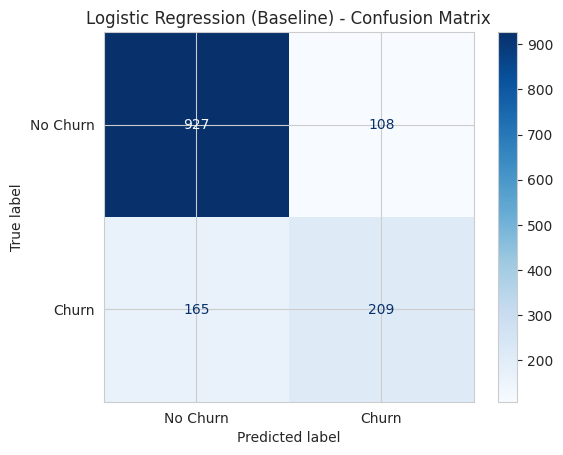

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

# Draws the 4-box table of correct and wrong predictions
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr_base, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Logistic Regression (Baseline) - Confusion Matrix")
plt.show()

The confusion matrix shows the baseline model correctly classified 927 non-churners and 209 churners, but missed 165 churners (false negatives) and raised 108 false alarms (false positives). Missed churners are the more costly error for the business, since these customers leave without any retention attempt, whereas a false alarm only costs an unnecessary retention offer. Reducing false negatives is therefore the main goal of tuning.

### 5.2 Hyperparameter Tuning

In [21]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Settings to try for Logistic Regression
param_grid_lr = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"]
}

# 5-fold cross-validation that keeps the churn ratio in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tries every combination and scores each one with F1
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid_lr,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

# Runs the search on the training data only
grid_lr.fit(X_train, y_train)

print("Best settings:", grid_lr.best_params_)
print("Best cross-validation F1:", round(grid_lr.best_score_, 4))

# The best model, already retrained on all training data
lr_tuned = grid_lr.best_estimator_

Best settings: {'C': 0.1, 'class_weight': 'balanced'}
Best cross-validation F1: 0.6301


In [22]:
# Table of every combination tried and its average CV F1
results_lr = pd.DataFrame(grid_lr.cv_results_)
results_lr = results_lr[["param_C", "param_class_weight", "mean_test_score"]]
results_lr = results_lr.sort_values("mean_test_score", ascending=False)
results_lr.round(4)

,param_C,param_class_weight,mean_test_score
3,0.10,balanced,0.6301
5,1.00,balanced,0.6296
7,10.00,balanced,0.6274
1,0.01,balanced,0.6272
9,100.00,balanced,0.6271
6,10.00,None,0.5978
8,100.00,None,0.5974
4,1.00,None,0.5936
2,0.10,None,0.5894
0,0.01,None,0.5638


**Tuning findings:**
- Hyperparameters were tuned using GridSearchCV with stratified 5-fold cross-validation on the training set only, so the test set stayed untouched for final evaluation.
- Two hyperparameters were searched: C (regularisation strength: 0.01, 0.1, 1, 10, 100) and class_weight (None or "balanced"), giving 10 combinations and 50 model fits.
- F1-score was used to select the best model because it balances precision and recall. Accuracy would favour the majority "No Churn" class, and recall alone could be maximised by predicting churn for everyone.
- The best combination was C = 0.1 and class_weight = "balanced", with a mean cross-validation F1 of 0.630.
- All five balanced settings (F1 0.627–0.630) outperformed all five unweighted settings (F1 0.564–0.598). This shows that handling class imbalance had a much larger effect than regularisation strength, which changed F1 by less than 0.003 once class weighting was applied.
- The weakest setting (C = 0.01, no class weighting) combined strong regularisation with no imbalance handling, leading to underfitting and poor detection of churners.
- The best model was automatically refitted on the full training set before being evaluated on the test set.

### 5.3 Tuned Model Evaluation

In [23]:
# Calculates the 5 metrics for one model and returns them together
def get_scores(y_true, y_pred, y_prob):
    scores = {
        "Accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "Precision": round(float(precision_score(y_true, y_pred)), 4),
        "Recall": round(float(recall_score(y_true, y_pred)), 4),
        "F1": round(float(f1_score(y_true, y_pred)), 4),
        "ROC-AUC": round(float(roc_auc_score(y_true, y_prob)), 4)
    }
    return scores

In [24]:
# Predicts with the tuned model on the test customers
y_pred_lr_tuned = lr_tuned.predict(X_test)
y_prob_lr_tuned = lr_tuned.predict_proba(X_test)[:, 1]

# Gets the metrics for both versions
lr_base_scores = get_scores(y_test, y_pred_lr_base, y_prob_lr_base)
lr_tuned_scores = get_scores(y_test, y_pred_lr_tuned, y_prob_lr_tuned)

# Puts baseline and tuned side by side
lr_comparison = pd.DataFrame([lr_base_scores, lr_tuned_scores],
                             index=["LR Baseline", "LR Tuned"])
lr_comparison

,Accuracy,Precision,Recall,F1,ROC-AUC
LR Baseline,0.8062,0.6593,0.5588,0.6049,0.8422
LR Tuned,0.7431,0.5105,0.7834,0.6181,0.8413


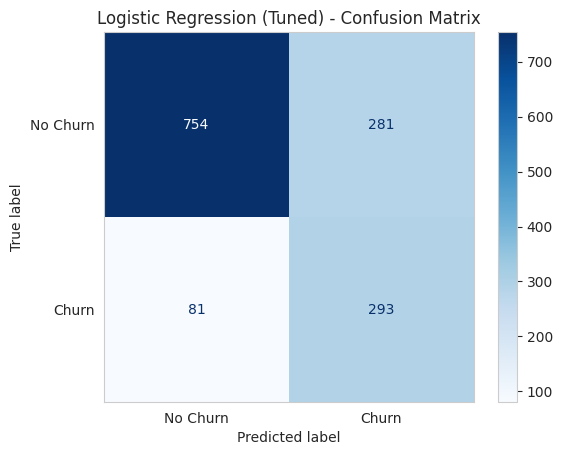

In [25]:
# Draws the 4-box table for the tuned model
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr_tuned,
                                        display_labels=["No Churn", "Churn"],
                                        cmap="Blues")
plt.title("Logistic Regression (Tuned) - Confusion Matrix")
plt.grid(False)
plt.show()

**Tuned Logistic Regression results:**
After tuning, recall rose from 0.56 to 0.78: the model correctly identified 293 of 374 churners, reducing missed churners from 165 to 81. This came at the cost of precision (0.66 to 0.51) and accuracy (0.81 to 0.74), as false alarms increased from 108 to 281. This trade-off is expected, since class weighting makes the model more willing to predict churn. F1 improved slightly (0.605 to 0.618), while ROC-AUC remained almost unchanged (0.842 to 0.841), indicating that tuning mainly shifted the decision boundary rather than improving the model's ranking ability. For churn prediction, the tuned model is preferable because a missed churner (a lost customer) is far more costly than a false alarm (an unnecessary retention offer).

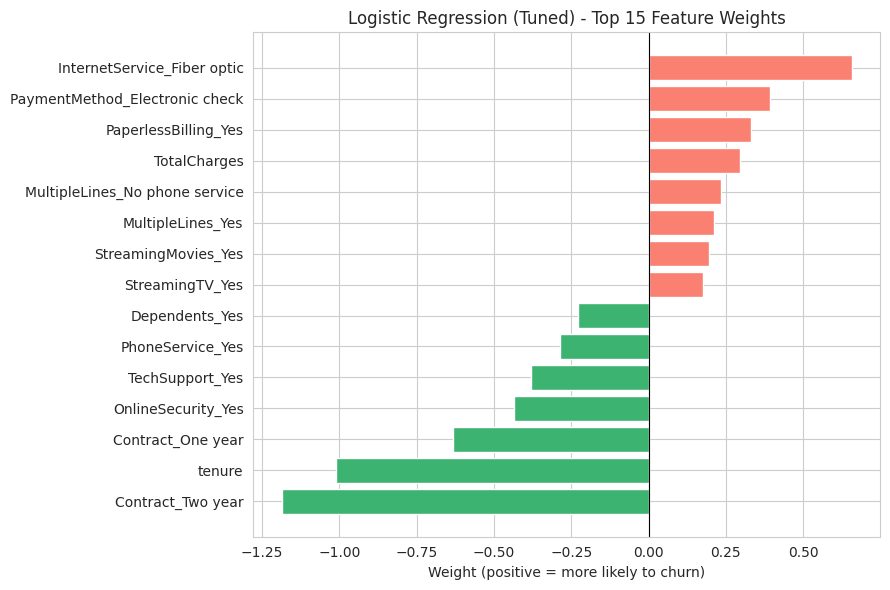

In [26]:
# Puts each feature next to the tuned model's weight
lr_weights = pd.DataFrame({
    "Feature": X_train.columns,
    "Weight": lr_tuned.coef_[0]
})

# Keeps the 15 features with the biggest effect (positive or negative)
lr_weights["Size"] = lr_weights["Weight"].abs()
lr_weights = lr_weights.sort_values("Size", ascending=False).head(15)
lr_weights = lr_weights.sort_values("Weight")

# Red bars push towards churn, green bars push towards staying
colours = []
for w in lr_weights["Weight"]:
    if w > 0:
        colours.append("salmon")
    else:
        colours.append("mediumseagreen")

plt.figure(figsize=(9, 6))
plt.barh(lr_weights["Feature"], lr_weights["Weight"], color=colours)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression (Tuned) - Top 15 Feature Weights")
plt.xlabel("Weight (positive = more likely to churn)")
plt.tight_layout()
plt.show()

**Feature weights (explainability):**
The tuned Logistic Regression coefficients show the direction and strength of each feature's effect on churn. Fiber optic internet, electronic check payments and paperless billing increase churn likelihood, while two-year and one-year contracts, longer tenure, online security and tech support reduce it. These directions match the EDA findings. TotalCharges has a positive coefficient despite churners having lower total charges in the EDA; this is due to its strong correlation with tenure (r = 0.83). Holding tenure fixed, higher TotalCharges effectively means a higher monthly bill, so its coefficient should not be interpreted in isolation.

**Section 5 findings (Logistic Regression):**
- The baseline model (default settings) achieved 80.6% accuracy but only 0.56 recall, missing 165 of 374 churners, because the class imbalance led it to favour predicting "No Churn".
- GridSearchCV with stratified 5-fold cross-validation, optimising F1, selected C = 0.1 and class_weight = "balanced". All balanced settings outperformed all unweighted settings, showing that handling class imbalance mattered far more than regularisation strength.
- The tuned model raised recall to 0.78 (missed churners reduced from 165 to 81) and F1 to 0.618, while precision fell to 0.51 and accuracy to 0.74 due to more false alarms (281).
- ROC-AUC stayed at ~0.84 for both, meaning tuning shifted the decision threshold rather than improving ranking ability.
- The model's weights are directly interpretable and agree with the EDA, which supports explainability.
- Since missing a churner is more costly than an unnecessary retention offer, the tuned model is the better choice for this business problem.

## 6. K-Nearest Neighbours (KNN)

### 6.1 Baseline Model

In [27]:
from sklearn.neighbors import KNeighborsClassifier

# Creates a KNN model with default settings (5 neighbours)
knn_base = KNeighborsClassifier()

# Stores the training customers and their answers
knn_base.fit(X_train, y_train)

# Predicts churn (1 or 0) for the test customers
y_pred_knn_base = knn_base.predict(X_test)

# Predicts the probability of churn for the test customers
y_prob_knn_base = knn_base.predict_proba(X_test)[:, 1]

print("Model trained.")
print("First 10 predictions:", y_pred_knn_base[:10])
print("First 10 probabilities:", y_prob_knn_base[:10])

Model trained.
First 10 predictions: [0 1 0 0 0 1 1 0 0 1]
First 10 probabilities: [0.  0.8 0.  0.4 0.  0.6 0.6 0.2 0.  0.8]


In [28]:
# Gets the 5 metrics for baseline KNN
knn_base_scores = get_scores(y_test, y_pred_knn_base, y_prob_knn_base)
print(knn_base_scores)

# Full report for both classes
print("\n", classification_report(y_test, y_pred_knn_base, target_names=["No Churn", "Churn"]))

{'Accuracy': 0.763, 'Precision': 0.5538, 'Recall': 0.5508, 'F1': 0.5523, 'ROC-AUC': 0.7929}

               precision    recall  f1-score   support

    No Churn       0.84      0.84      0.84      1035
       Churn       0.55      0.55      0.55       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.76      0.76      0.76      1409



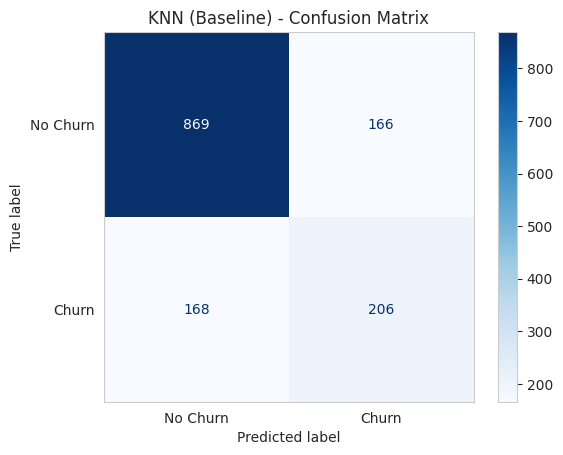

In [29]:
# Draws the 4-box table for baseline KNN
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn_base,display_labels=["No Churn", "Churn"],cmap="Blues")
plt.title("KNN (Baseline) - Confusion Matrix")
plt.grid(False)
plt.show()

The baseline KNN (K = 5) achieved 76.3% accuracy, 0.55 precision, 0.55 recall, 0.55 F1 and 0.79 ROC-AUC, underperforming the baseline Logistic Regression. It caught a similar number of churners (206 vs 209) but produced more false alarms (166 vs 108). This is likely because KNN weights all features equally in its distance calculation, unlike Logistic Regression, which learns which features matter most; many binary one-hot features also make distances less informative. With K = 5, predicted probabilities can only take six values, limiting its ranking ability (lower ROC-AUC). KNN also has no class_weight option, so the majority class dominates each customer's neighbours.

### 6.2 Hyperparameter Tuning

In [30]:
# Settings to try for KNN
param_grid_knn = { "n_neighbors": [3, 5, 7, 9, 11, 15, 19, 25, 31, 41, 51, 61, 75], "weights": ["uniform", "distance"], "metric": ["euclidean", "manhattan"]}

# Tries every combination using the same 5-fold practice exams as LR
grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid_knn,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

# Runs the search on the training data only
grid_knn.fit(X_train, y_train)

print("Best settings:", grid_knn.best_params_)
print("Best cross-validation F1:", round(grid_knn.best_score_, 4))

# The best KNN model, already retrained on all training data
knn_tuned = grid_knn.best_estimator_

Best settings: {'metric': 'manhattan', 'n_neighbors': 41, 'weights': 'uniform'}
Best cross-validation F1: 0.6076


In [31]:
# Table of the 10 best combinations and their average CV F1
results_knn = pd.DataFrame(grid_knn.cv_results_)
results_knn = results_knn[["param_n_neighbors", "param_weights", "param_metric", "mean_test_score"]]
results_knn = results_knn.sort_values("mean_test_score", ascending=False)
results_knn.head(10).round(4)

,param_n_neighbors,param_weights,param_metric,mean_test_score
44,41,uniform,manhattan,0.6076
16,31,uniform,euclidean,0.6037
18,41,uniform,euclidean,0.6031
42,31,uniform,manhattan,0.6013
50,75,uniform,manhattan,0.6000
14,25,uniform,euclidean,0.5999
40,25,uniform,manhattan,0.5999
48,61,uniform,manhattan,0.5999
22,61,uniform,euclidean,0.5990
46,51,uniform,manhattan,0.5988


**KNN tuning findings:**
- KNN was tuned using GridSearchCV with the same stratified 5-fold cross-validation folds as Logistic Regression, optimising F1, so both models were compared fairly.
- Three hyperparameters were searched: the number of neighbours (K: 3 to 75), the voting method (uniform or distance-weighted) and the distance metric (Euclidean or Manhattan).
- The initial search selected K = 31, the largest value tested, suggesting the best K could lie beyond the grid. The grid was therefore extended to K = 75, and the best setting became K = 41 with Manhattan distance and uniform weights (mean CV F1 = 0.608). Larger values (51, 61, 75) performed worse, confirming 41 as a genuine optimum rather than a boundary effect.
- Larger K performed better than the default K = 5 because votes from more neighbours are less affected by individual unusual customers, giving more stable predictions and smoother probabilities.
- Uniform voting outperformed distance weighting, as distance weighting lets the closest one or two neighbours dominate, reintroducing noise.
- KNN has no class_weight option, so class imbalance could not be addressed through tuning.

### 6.3 Tuned Model Evaluation

In [32]:
# Predicts with the tuned KNN on the test customers
y_pred_knn_tuned = knn_tuned.predict(X_test)
y_prob_knn_tuned = knn_tuned.predict_proba(X_test)[:, 1]

# Gets the metrics for both KNN versions
knn_tuned_scores = get_scores(y_test, y_pred_knn_tuned, y_prob_knn_tuned)

# Puts baseline and tuned KNN side by side
knn_comparison = pd.DataFrame([knn_base_scores, knn_tuned_scores],
                              index=["KNN Baseline", "KNN Tuned"])
knn_comparison

,Accuracy,Precision,Recall,F1,ROC-AUC
KNN Baseline,0.7630,0.5538,0.5508,0.5523,0.7929
KNN Tuned,0.7899,0.6096,0.5802,0.5945,0.8309


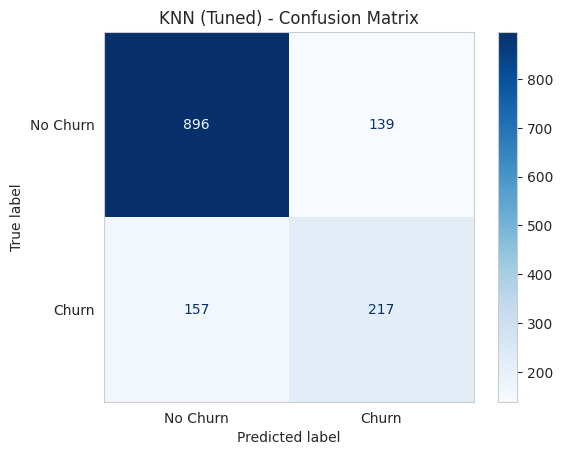

In [33]:
# Draws the 4-box table for tuned KNN
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn_tuned,
                                        display_labels=["No Churn", "Churn"],
                                        cmap="Blues")
plt.title("KNN (Tuned) - Confusion Matrix")
plt.grid(False)
plt.show()

**Tuned KNN results:**
Tuning improved every metric. Accuracy rose from 0.763 to 0.790, precision from 0.554 to 0.610, recall from 0.551 to 0.580, F1 from 0.552 to 0.595 and ROC-AUC from 0.793 to 0.831. The tuned model caught 217 churners (up from 206), missed 157 (down from 168) and raised 139 false alarms (down from 166), so it reduced both types of error. The large rise in ROC-AUC is mainly because, with 41 neighbours, predicted probabilities take many more possible values, allowing customers to be ranked by risk more finely.

However, the tuned KNN still performed worse than the tuned Logistic Regression at detecting churners, missing 157 churners compared with 81 (recall 0.58 vs 0.78). Without a class_weight option, the majority "No Churn" class continues to dominate each customer's neighbourhood.

**Section 6 findings (KNN):**
- KNN predicts churn by finding the K most similar training customers using a distance measure and taking a majority vote. It does not learn weights; training simply stores the data, and all computation happens at prediction time.
- Because KNN relies on distance, feature scaling (Section 4) was essential; without it, TotalCharges would have dominated the distance calculation.
- The baseline model (K = 5) performed worse than the baseline Logistic Regression (F1 0.552 vs 0.605, ROC-AUC 0.793 vs 0.842). KNN treats all features as equally important, and the many binary one-hot features make distances less informative.
- Tuning selected K = 41, Manhattan distance and uniform weights, improving F1 to 0.595 and ROC-AUC to 0.831 while reducing both missed churners and false alarms.
- Even after tuning, KNN's recall (0.58) remained well below the tuned Logistic Regression (0.78), because KNN cannot reweight classes to handle imbalance.
- KNN is also slower at prediction time, since it must compare each new customer with every training customer, which would be a limitation for large-scale deployment.

## 7. Random Forest

### 7.1 Baseline Model

In [34]:
from sklearn.ensemble import RandomForestClassifier

# Creates a Random Forest with default settings (100 trees)
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

# Builds the 100 trees from the training customers
rf_base.fit(X_train, y_train)

# Predicts churn (1 or 0) and the probability of churn for the test customers
y_pred_rf_base = rf_base.predict(X_test)
y_prob_rf_base = rf_base.predict_proba(X_test)[:, 1]

# Checks accuracy on the training data vs the test data
print("Training accuracy:", round(rf_base.score(X_train, y_train), 4))
print("Test accuracy    :", round(rf_base.score(X_test, y_test), 4))

# Gets the 5 metrics for baseline Random Forest
rf_base_scores = get_scores(y_test, y_pred_rf_base, y_prob_rf_base)
print(rf_base_scores)

Training accuracy: 0.998
Test accuracy    : 0.785
{'Accuracy': 0.785, 'Precision': 0.6187, 'Recall': 0.4947, 'F1': 0.5498, 'ROC-AUC': 0.8248}


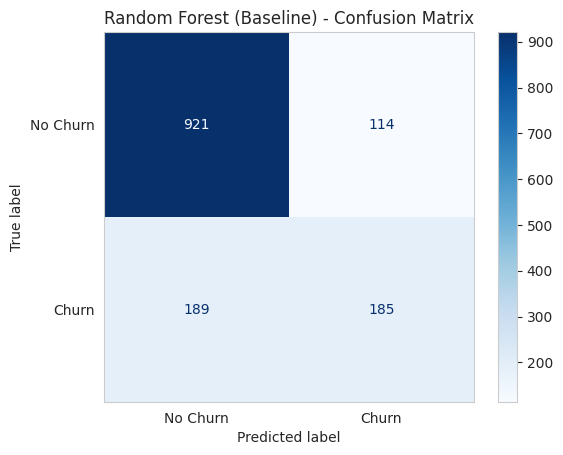

In [35]:
# Draws the 4-box table for baseline Random Forest
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf_base,
                                        display_labels=["No Churn", "Churn"],
                                        cmap="Blues")
plt.title("Random Forest (Baseline) - Confusion Matrix")
plt.grid(False)
plt.show()

The baseline Random Forest (100 trees, default settings) achieved 99.8% training accuracy but only 78.5% test accuracy, indicating strong overfitting: with no depth limit, the trees grew until they had effectively memorised the training customers. It had the lowest recall of the three baselines (0.49), missing more than half of the churners, because the fully grown trees strongly learned that most customers stay and no class weighting was applied. Its ROC-AUC (0.825) was better than KNN but below Logistic Regression, showing reasonable ranking ability but an overly cautious decision threshold.

### 7.2 Hyperparameter Tuning

In [36]:
# Settings to try for Random Forest
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [1, 5, 10],
    "class_weight": [None, "balanced"]
}

# Tries every combination using the same 5-fold practice exams
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=cv, scoring="f1", n_jobs=-1)

# Runs the search on the training data only
grid_rf.fit(X_train, y_train)

print("Best settings:", grid_rf.best_params_)
print("Best cross-validation F1:", round(grid_rf.best_score_, 4))

# The best Random Forest, already retrained on all training data
rf_tuned = grid_rf.best_estimator_

Best settings: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 10, 'n_estimators': 200}
Best cross-validation F1: 0.6397


In [37]:
# Table of the 10 best combinations and their average CV F1
results_rf = pd.DataFrame(grid_rf.cv_results_)
results_rf = results_rf[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
                         "param_class_weight", "mean_test_score"]]
results_rf = results_rf.sort_values("mean_test_score", ascending=False)
results_rf.head(10).round(4)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score
35,200,10,10,balanced,0.6397
46,100,None,10,balanced,0.6393
34,100,10,10,balanced,0.6385
38,100,15,5,balanced,0.6381
41,200,15,10,balanced,0.6367
40,100,15,10,balanced,0.6365
32,100,10,5,balanced,0.6363
39,200,15,5,balanced,0.6362
47,200,None,10,balanced,0.6359
33,200,10,5,balanced,0.6357


**Random Forest tuning findings:**
- Random Forest was tuned using GridSearchCV with the same stratified 5-fold cross-validation folds as the other models, optimising F1.
- Four hyperparameters were searched: n_estimators (100, 200), max_depth (5, 10, 15, None), min_samples_leaf (1, 5, 10) and class_weight (None, "balanced"), giving 48 combinations and 240 model fits.
- The best combination was class_weight = "balanced", max_depth = 10, min_samples_leaf = 10 and n_estimators = 200 (mean CV F1 = 0.640).
- All ten best configurations used balanced class weights, again showing that handling class imbalance was the most important setting.
- Limiting tree depth and requiring at least 10 customers per leaf stops trees from creating rules for individual customers, which reduces overfitting.

### 7.3 Tuned Model Evaluation

In [38]:
# Predicts with the tuned Random Forest on the test customers
y_pred_rf_tuned = rf_tuned.predict(X_test)
y_prob_rf_tuned = rf_tuned.predict_proba(X_test)[:, 1]

# Checks whether the training/test gap has closed
print("Training accuracy:", round(rf_tuned.score(X_train, y_train), 4))
print("Test accuracy    :", round(rf_tuned.score(X_test, y_test), 4))

# Puts baseline and tuned Random Forest side by side
rf_tuned_scores = get_scores(y_test, y_pred_rf_tuned, y_prob_rf_tuned)
rf_comparison = pd.DataFrame([rf_base_scores, rf_tuned_scores],
                             index=["RF Baseline", "RF Tuned"])
rf_comparison

Training accuracy: 0.8014
Test accuracy    : 0.7594


,Accuracy,Precision,Recall,F1,ROC-AUC
RF Baseline,0.7850,0.6187,0.4947,0.5498,0.8248
RF Tuned,0.7594,0.5321,0.7754,0.6311,0.8445


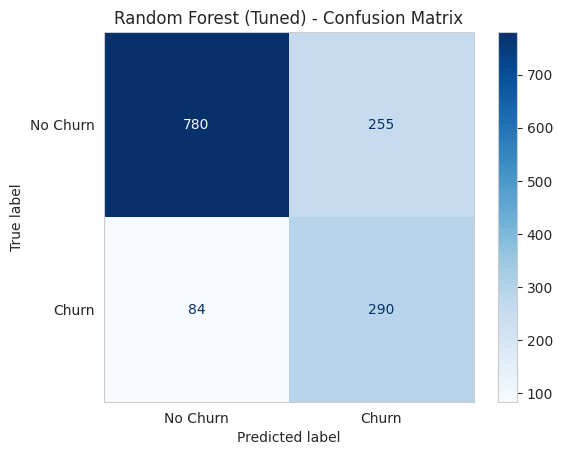

In [39]:
# Draws the 4-box table for tuned Random Forest
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf_tuned,
                                        display_labels=["No Churn", "Churn"],
                                        cmap="Blues")
plt.title("Random Forest (Tuned) - Confusion Matrix")
plt.grid(False)
plt.show()

**Tuned Random Forest results:**
Limiting tree depth and leaf size fixed the overfitting: the gap between training and test accuracy fell from 0.21 (0.998 vs 0.785) to 0.04 (0.801 vs 0.759).

The tuned model caught 290 of 374 churners, reducing missed churners from 189 to 84 and raising recall from 0.49 to 0.78. False alarms increased from 114 to 255, lowering precision from 0.62 to 0.53. F1 rose from 0.550 to 0.631 and ROC-AUC from 0.825 to 0.845, the highest of all models. Compared with the tuned Logistic Regression, the tuned Random Forest missed a similar number of churners (84 vs 81) while producing 26 fewer false alarms.

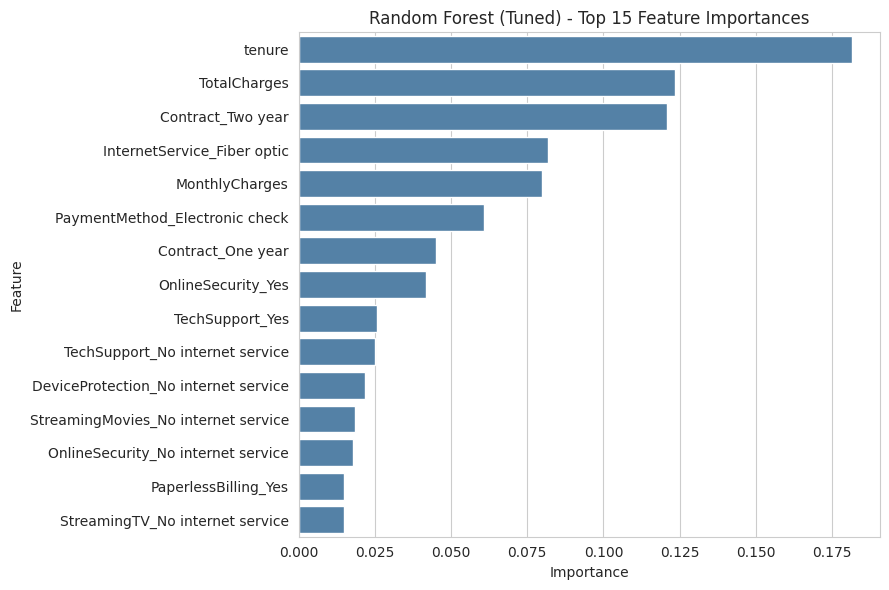

In [40]:
# Puts each feature next to its importance score
importance_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_tuned.feature_importances_
})

# Keeps the 15 most important features
importance_table = importance_table.sort_values("Importance", ascending=False).head(15)

# Horizontal bar chart, most important at the top
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_table, x="Importance", y="Feature", color="steelblue")
plt.title("Random Forest (Tuned) - Top 15 Feature Importances")
plt.tight_layout()
plt.show()

**Feature importance (explainability):**
Feature importance from the tuned Random Forest showed tenure as the most influential feature, followed by TotalCharges, Contract_Two year, InternetService_Fiber optic, MonthlyCharges and PaymentMethod_Electronic check. This closely matches the EDA findings and the Logistic Regression weights, indicating that contract type, tenure, internet service and payment method are consistent drivers of churn across different models. Demographic features such as gender did not appear among the top 15, suggesting predictions are driven mainly by contract and service characteristics. Feature importance shows how much each feature contributes but not the direction of its effect; the EDA and Logistic Regression weights provide that.

**Section 7 findings (Random Forest):**
- Random Forest builds many decision trees, each trained on a random sample of customers and considering random subsets of features at each split, and combines them by majority vote.
- The baseline model (100 fully grown trees) overfitted heavily: 99.8% training accuracy vs 78.5% test accuracy. It had the lowest baseline recall (0.49), missing 189 of 374 churners.
- Tuning selected class_weight = "balanced", max_depth = 10, min_samples_leaf = 10 and 200 trees, reducing the training/test accuracy gap from 0.21 to 0.04.
- The tuned model achieved recall 0.78, F1 0.631 and ROC-AUC 0.845 (the highest F1 and ROC-AUC of all models), missing 84 churners with 255 false alarms.
- Random Forest does not need feature scaling, can capture interactions between features (e.g. new customer + month-to-month + fiber), and provides feature importance that agrees with the EDA.

## 8. Model Comparison

In [42]:
# Puts all 6 results into one table
all_results = pd.DataFrame(
    [lr_base_scores, lr_tuned_scores,
     knn_base_scores, knn_tuned_scores,
     rf_base_scores, rf_tuned_scores],
    index=["LR Baseline", "LR Tuned",
           "KNN Baseline", "KNN Tuned",
           "RF Baseline", "RF Tuned"]
)

# Highlights the best value in each column
all_results.style.highlight_max(axis=0, color="seagreen").format("{:.4f}")

,Accuracy,Precision,Recall,F1,ROC-AUC
LR Baseline,0.8062,0.6593,0.5588,0.6049,0.8422
LR Tuned,0.7431,0.5105,0.7834,0.6181,0.8413
KNN Baseline,0.7630,0.5538,0.5508,0.5523,0.7929
KNN Tuned,0.7899,0.6096,0.5802,0.5945,0.8309
RF Baseline,0.7850,0.6187,0.4947,0.5498,0.8248
RF Tuned,0.7594,0.5321,0.7754,0.6311,0.8445


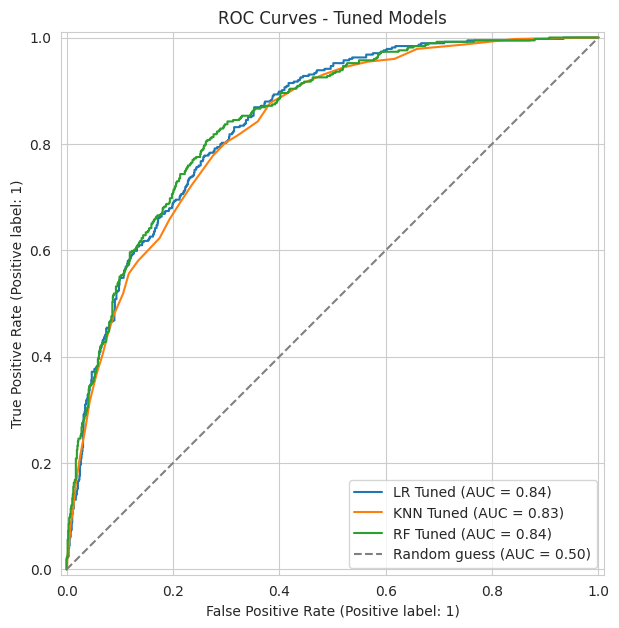

In [44]:
from sklearn.metrics import RocCurveDisplay

# Draws one ROC curve per tuned model on the same chart
fig, ax = plt.subplots(figsize=(7, 8))
RocCurveDisplay.from_predictions(y_test, y_prob_lr_tuned, name="LR Tuned", ax=ax)
RocCurveDisplay.from_predictions(y_test, y_prob_knn_tuned, name="KNN Tuned", ax=ax)
RocCurveDisplay.from_predictions(y_test, y_prob_rf_tuned, name="RF Tuned", ax=ax)

# Diagonal line showing random guessing
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess (AUC = 0.50)")

ax.set_title("ROC Curves - Tuned Models")
ax.legend(loc="lower right")
plt.show()

The ROC curves show that all three tuned models perform well above random guessing. Logistic Regression and Random Forest are almost identical (AUC ≈ 0.84), with KNN slightly lower (AUC = 0.83).

**Section 8 findings (Model Comparison):**
- The baseline Logistic Regression had the highest accuracy (0.806), but it missed 165 of 374 churners, so accuracy was not used to choose the best model.
- Tuning improved the F1-score of every model. For Logistic Regression and Random Forest, this came mainly from class weighting, which helped the models catch far more churners.
- KNN performed worst (F1 0.595) and still missed 157 churners after tuning.
- The tuned Logistic Regression and tuned Random Forest performed similarly, both catching about 78% of churners.

**Selected model: Tuned Random Forest.** It achieved the highest F1 (0.631) and ROC-AUC (0.845), catching 290 of 374 churners with fewer false alarms than Logistic Regression (255 vs 281).

The tuned Logistic Regression is a good alternative when explainability matters, because its weights show clearly how each feature affects churn.

## 9. AI Ethics and Post-Deployment Strategies

### 9.1 Ethical strategies followed during development

**1. Fairness and bias**
- The dataset contains sensitive attributes such as gender and SeniorCitizen (age group). These could lead to customers being treated differently because of who they are rather than how they use the service.
- The Random Forest feature importance and Logistic Regression weights showed that gender was not among the important features; predictions were driven mainly by contract type, tenure, internet service and payment method.
- However, senior citizens had a higher churn rate (~42% vs ~24%), so the model may flag them more often. In practice, the model's errors should be checked separately for groups such as senior citizens to make sure no group is treated unfairly. Sensitive attributes could also be removed from the model if they are not needed.

**2. Handling class imbalance responsibly**
- Only 26.5% of customers churned. A model trained without adjustment would mostly ignore churners.
- Class weighting and F1-based tuning were used so that churners were not overlooked, rather than reporting a misleadingly high accuracy.

**3. Transparency and explainability**
- Logistic Regression weights and Random Forest feature importances were used to explain which factors drive predictions, and both agreed with the EDA.
- This means the business can explain why a customer was flagged (e.g. month-to-month contract, short tenure), rather than relying on a "black box".
- KNN was noted as harder to explain, since it relies on similar customers rather than learned rules.

**4. Honest and reproducible evaluation**
- The test set was kept separate and only used once for final evaluation, and the scaler was fitted on training data only to prevent data leakage.
- random_state = 42 was used throughout so that all results can be reproduced.
- Multiple metrics were reported, including the trade-off between catching churners and raising false alarms, rather than only the best-looking number.

**5. Privacy and data protection**
- customerID was removed, and the model does not use names, contact details or other directly identifying information.
- In a real deployment, customer data must be stored securely, used only for the stated purpose, and handled in line with data protection laws such as GDPR (or Sri Lanka's Personal Data Protection Act), including being clear with customers about how their data is used.

**6. Responsible use of predictions**
- The tuned model raises around 255 false alarms out of 1,035 loyal customers. These customers should only receive helpful retention offers (such as discounts or better plans), never pressure tactics or penalties.
- Predictions should support human decisions, not replace them.

### 9.2 Post-deployment strategies

**1. Monitor performance**
- Track recall, precision and F1 on new customers over time, comparing predictions with who actually churned.
- Set alerts if performance drops below an agreed level.

**2. Watch for data drift**
- Customer behaviour, prices and services change over time (e.g. new plans, competitor offers). This is called data drift, and it can make the model less accurate.
- Regularly compare new data with the training data (e.g. the mix of contract types or average monthly charges).

**3. Retrain regularly**
- Retrain the model on recent data on a schedule (e.g. every few months) or when drift or a performance drop is detected, repeating the same preprocessing and tuning steps.
- Keep versions of each model so an older version can be restored if a new one performs worse.

**4. Ongoing fairness checks**
- Regularly check whether some groups (e.g. senior citizens) are flagged or missed much more often than others, and adjust the model if they are.

**5. Keep a human in the loop**
- Retention teams should review flagged customers before taking action, and customers should be able to question or opt out of automated decisions.

**6. Adjust the decision threshold**
- The 0.5 cut-off can be changed as business needs change. For example, lower it to catch more churners if retention offers are cheap, or raise it if offers are expensive.

**7. Security and documentation**
- Protect the model and customer data from unauthorised access, and document how the model was built, what data it uses and its known limitations so others can understand and audit it.

### 9.3 Limitations and further enhancements

**Limitations**
- The dataset is a single snapshot from one (fictional) company, so the model may not generalise to other companies or time periods.
- TotalCharges is highly correlated with tenure, making Logistic Regression weights harder to interpret.
- KNN cannot handle class imbalance directly, which limited its recall.
- The default 0.5 threshold was used for all models.

**Further enhancements**
- Try other imbalance methods, such as SMOTE (creating synthetic churn examples), or tune the decision threshold.
- Try more advanced models such as gradient boosting (e.g. XGBoost).
- Use SHAP (a method that explains each individual prediction) for more detailed explainability.
- Estimate the business cost of each error type to choose the threshold that saves the most money.